[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jinming99/learn-ml-by-building/blob/main/Lecture%2012%20PCA/12-PCA.ipynb)

# Lecture 12: PCA and Nonlinear Dimensionality Reduction

A text can become a vector with hundreds of coordinates. We would like to draw it on a page—but which relationships survive the trip? We'll use PCA to understand what a projection keeps, compare it with t-SNE and UMAP, and return to a real collection of human and AI-generated essays to see what a map can actually tell us.

The text examples use the [DAIGT V3 dataset](https://www.kaggle.com/datasets/thedrcat/daigt-v3-train-dataset), with inspiration from [Yang Lu's embedding analysis](https://medium.com/@uwyang/visualizing-ai-v-s-human-writing-embeddings-using-tsne-for-ai-detection-part-1-n-5df14ef9e6ef). These are exploratory plots of a historical dataset, not a validated AI detector.

**Data and environment.** The local CSV/embedding pairs and mammoth point cloud are described in [data/README.md](data/README.md); they are not bundled with the public notebook. This notebook needs NumPy, pandas, Matplotlib, scikit-learn, and `umap-learn`. The cached embeddings avoid downloading or running a language model during class.
In Colab, the setup below installs the packages; the prepared data files must also be placed in the lecture's `data/` folder before running the examples.

In [13]:
# @title Colab Setup
import os
import sys
import subprocess
from pathlib import Path

if 'google.colab' in sys.modules:
    repository = Path('/content/learn-ml-by-building')
    if not repository.exists():
        subprocess.check_call(['git', 'clone', '--depth', '1',
                               'https://github.com/jinming99/learn-ml-by-building.git', str(repository)])
    os.chdir(repository / 'Lecture 12 PCA')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q',
                           'numpy', 'pandas', 'matplotlib', 'scikit-learn>=1.5', 'umap-learn', 'ipywidgets'])
    print('Packages ready. Place the prepared CSV, embedding NPZ, and mammoth CSV in data/.')
else:
    print('Running locally; using the prepared data in the lecture folder.')

Running locally; using the prepared data in the lecture folder.


In [14]:
from io import BytesIO
from html import escape
import base64
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.datasets import make_swiss_roll
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.feature_extraction.text import CountVectorizer
from threadpoolctl import threadpool_limits
from umap import UMAP

BLUE, CORAL, TEAL, INK = '#3A86FF', '#E76F51', '#2A9D8F', '#263238'
SOURCE_COLORS = [BLUE, CORAL]
plt.rcParams.update({'figure.dpi': 110, 'font.size': 12, 'axes.titlesize': 14,
                     'axes.labelcolor': INK, 'text.color': INK, 'axes.spines.top': False,
                     'axes.spines.right': False, 'legend.frameon': False,
                     'axes.grid': True, 'grid.alpha': .16})


def figure_switch(figures, label, slider=False):
    """Saved HTML controls; the first frame also serves as a static preview."""
    frames = []
    for name, fig in figures:
        buf = BytesIO()
        fig.savefig(buf, format='png', facecolor='white')
        frames.append((name, base64.b64encode(buf.getvalue()).decode()))
        plt.close(fig)
    change = ("this.closest('.figure-switch').querySelectorAll('img').forEach((im,i)=>"
              "{im.hidden=i!==Number(this.value);im.style.display=im.hidden?'none':'block'})")
    if slider:
        control = (f'<input type="range" min="0" max="{len(frames)-1}" value="0" '
                   f'style="width:400px;max-width:90%" oninput="{change}">')
    else:
        options = ''.join(f'<option value="{i}">{escape(name)}</option>'
                          for i, (name, _) in enumerate(frames))
        control = f'<select onchange="{change}" style="font-size:16px">{options}</select>'
    pictures = ''.join(f'<img alt="{escape(name)}" src="data:image/png;base64,{png}" '
                       f'style="width:100%;height:auto;display:{"none" if i else "block"}"'
                       f'{" hidden" if i else ""}>' for i, (name, png) in enumerate(frames))
    html = f'<div class="figure-switch"><label>{escape(label)} {control}</label>{pictures}</div>'
    display({'text/html': html, 'image/png': frames[0][1],
             'text/plain': label + ' — ' + frames[0][0]}, raw=True)


def tsne_map(points, perplexity=30):
    with threadpool_limits(limits=1):
        return TSNE(n_components=2, perplexity=perplexity, init='pca',
                    learning_rate='auto', max_iter=1000, random_state=42).fit_transform(points)


def map_axes(ax, title):
    ax.set(title=title, xticks=[], yticks=[])
    ax.grid(False)
    ax.spines[['left', 'bottom']].set_visible(False)
    ax.set_aspect('equal', adjustable='box')


data_dir = Path('data') if Path('data/daigt_sample_1000.csv').exists() else Path('Lecture 12 PCA/data')
csv_path = data_dir / 'daigt_sample_1000.csv'
if not csv_path.exists():
    raise FileNotFoundError('Prepare the matching CSV and NPZ files using data/README.md first.')
raw_essays = pd.read_csv(csv_path)
raw_embeddings = np.load(csv_path.with_name(csv_path.stem + '_embeddings.npz'))['embeddings']
assert raw_embeddings.shape == (len(raw_essays), 384) and np.isfinite(raw_embeddings).all()
# Keep the same rows, in the same order, in both files. These caches were generated as a pair.
unique_rows = ~raw_essays.text_normalized.duplicated()
essays = raw_essays.loc[unique_rows].reset_index(drop=True)
embeddings = raw_embeddings[unique_rows.to_numpy()]
print(f'{len(essays):,} distinct normalized essays • {embeddings.shape[1]} coordinates each')
print(f'{(~unique_rows).sum():,} repeated texts removed • {essays.prompt_name.nunique()} prompts')

14,004 distinct normalized essays • 384 coordinates each
996 repeated texts removed • 15 prompts


## 1. What Does This Map Tell Us?

Each dot is one essay. A sentence encoder has already converted its text to 384 numbers. PCA compresses those vectors to 30 coordinates; t-SNE arranges them on a page. We keep the locations fixed while coloring the same essays by their recorded origin or prompt. Which better explains the visible groups? We'll return to model family and length after narrowing the question to one prompt.

Only the embedding vectors determine the locations. The metadata supplies the colors afterward. We use the same 200 essays per prompt in every view. The cached [MiniLM encoder](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2) truncates inputs after 256 word pieces, so these embeddings describe the beginning of a long essay, not necessarily the whole text.

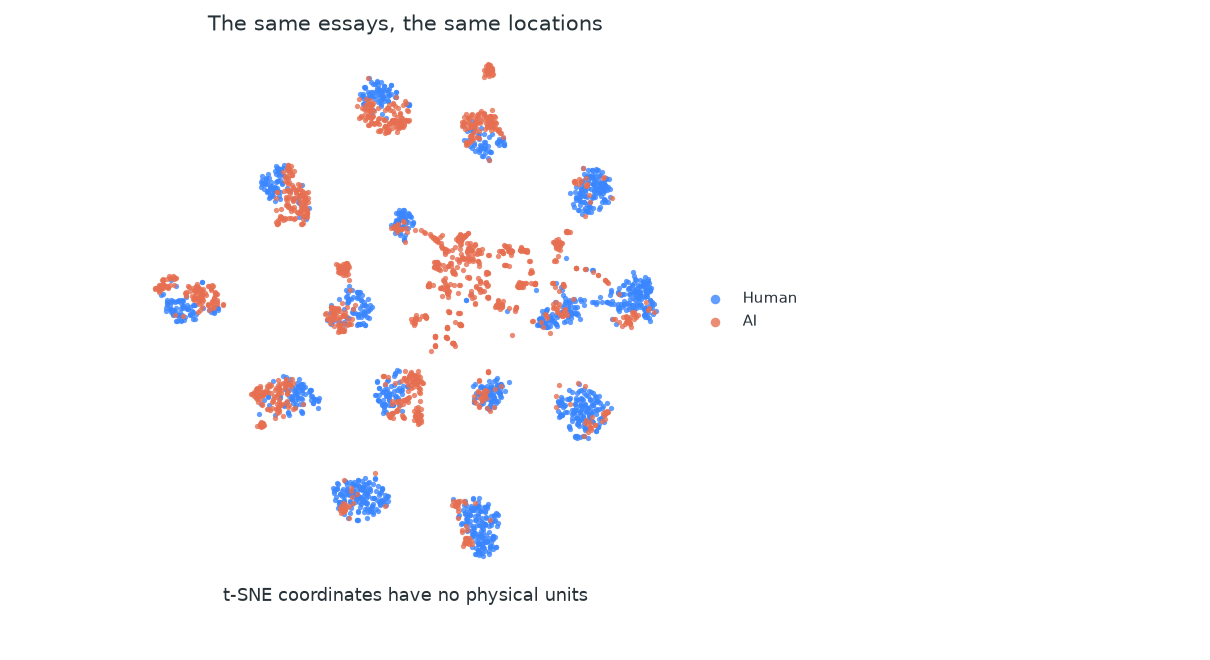

In [15]:
map_rows = essays.groupby('prompt_name', group_keys=False).sample(n=200, random_state=42).index.to_numpy()
map_meta = essays.iloc[map_rows]
with threadpool_limits(limits=1):
    text_pca = PCA(svd_solver='full').fit(embeddings)
    text_scores = text_pca.transform(embeddings)
text_map = tsne_map(text_scores[map_rows, :30])


def colored_text_map(ax, coordinates, metadata, field):
    if field == 'word_count':
        dots = ax.scatter(*coordinates.T, c=metadata[field], cmap='viridis', s=10, alpha=.75,
                          vmin=0, vmax=metadata[field].quantile(.98), linewidths=0)
        ax.figure.colorbar(dots, cax=ax.inset_axes([1.04, .15, .035, .7]),
                           label='Words in the full essay', extend='max')
    else:
        values = sorted(metadata[field].unique())
        colors = SOURCE_COLORS if field == 'label' else plt.get_cmap('tab20').colors
        for i, value in enumerate(values):
            mask = metadata[field].eq(value).to_numpy()
            name = ['Human', 'AI'][int(value)] if field == 'label' else str(value)
            color = colors[(i+2) % len(colors)] if field == 'model' else colors[i]
            if field == 'model' and value == 'human':
                color = BLUE
            ax.scatter(*coordinates[mask].T, color=color, label=name, s=12, alpha=.8, linewidths=0)
        ax.legend(loc='center left', bbox_to_anchor=(1.01, .5), fontsize=10, markerscale=1.8)
    map_axes(ax, 'The same essays, the same locations')
    ax.set_xlabel('t-SNE coordinates have no physical units')


text_views = []
for field, name in [('label', 'Recorded origin'), ('prompt_name', 'Essay prompt')]:
    fig = plt.figure(figsize=(11, 6))
    ax = fig.add_axes([.05, .12, .57, .82])
    colored_text_map(ax, text_map, map_meta, field)
    text_views.append((name, fig))
figure_switch(text_views, 'Color by:')

**Which words or phrases make you suspect that an essay was generated? Would the same clues ever appear in human writing?**

Let's connect those guesses to the actual vectors. PCA itself never sees the human/AI labels. We refit it on half the essays, then use their labels to choose one of the first 30 directions to investigate. We compare essays answering the same prompt when choosing that direction and checking its wording associations. The distributions, word associations, and classifier error rates below come from the other half; none of those essays chooses the direction or the classifier's cutoff.

The word counts use the opening 80 words, a readable window rather than the encoder's exact 256-word-piece limit. These are illustrative phrases, not an exhaustive list. Their correlations with a PCA coordinate are **associations, not the component's weights or a causal explanation**. This split tests other essays from the same collection, not new authors or unseen language models.

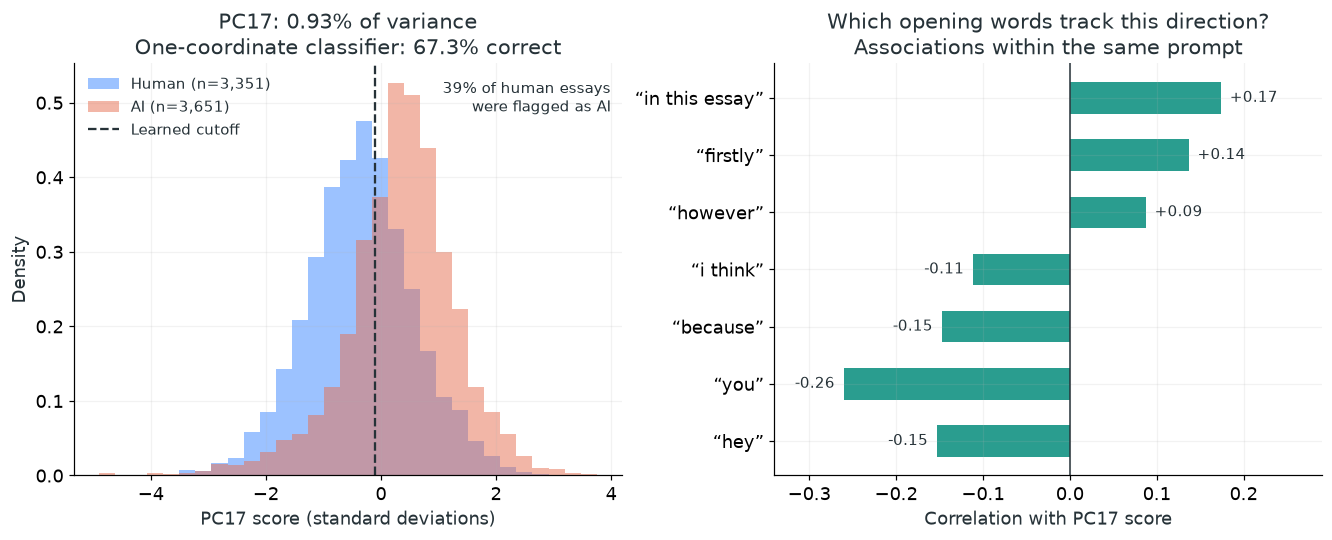

“Hey” in the opening 80 words: human 0.3%; AI 5.4%.


In [16]:
word_train, word_check = train_test_split(
    np.arange(len(essays)), test_size=.5, random_state=42,
    stratify=essays.prompt_name + '|' + essays.label.astype(str))
with threadpool_limits(limits=1):
    wording_pca = PCA(30, svd_solver='full').fit(embeddings[word_train])
    wording_scores = wording_pca.transform(embeddings)


def within_prompt(values, rows):
    frame = pd.DataFrame(values[rows])
    return (frame - frame.groupby(essays.prompt_name.iloc[rows].to_numpy()).transform('mean')).to_numpy()


# PCA supplies directions; labels choose a candidate and train a separate classifier.
label_residual = within_prompt(essays.label.to_numpy()[:, None], word_train)[:, 0]
pc_residual = within_prompt(wording_scores, word_train)
associations = np.array([np.corrcoef(pc_residual[:, j], label_residual)[0, 1] for j in range(30)])
word_pc = int(np.abs(associations).argmax())
word_coordinate = wording_scores[:, word_pc] * np.sign(associations[word_pc])
word_coordinate = (word_coordinate - word_coordinate[word_train].mean()) / word_coordinate[word_train].std()
word_classifier = LogisticRegression().fit(word_coordinate[word_train, None], essays.label.iloc[word_train])
word_predictions = word_classifier.predict(word_coordinate[word_check, None])
word_accuracy = (word_predictions == essays.label.iloc[word_check].to_numpy()).mean()
word_false_positive = word_predictions[essays.label.iloc[word_check].to_numpy() == 0].mean()
word_cutoff = -word_classifier.intercept_[0] / word_classifier.coef_[0, 0]

phrases = ['in this essay', 'firstly', 'however', 'i think', 'because', 'you', 'hey']
openings = essays.text_normalized.str.split().str[:80].str.join(' ')
phrase_present = CountVectorizer(vocabulary=phrases, binary=True, ngram_range=(1, 3),
                                 token_pattern=r'(?u)\b\w+\b').fit_transform(openings).toarray()
phrase_residual = within_prompt(phrase_present, word_check)
score_residual = within_prompt(word_coordinate[:, None], word_check)[:, 0]
phrase_correlations = np.array([np.corrcoef(phrase_residual[:, j], score_residual)[0, 1]
                                for j in range(len(phrases))])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), layout='constrained')
bins = np.linspace(word_coordinate[word_check].min(), word_coordinate[word_check].max(), 32)
for label, color in enumerate(SOURCE_COLORS):
    rows = word_check[essays.label.iloc[word_check].to_numpy() == label]
    axes[0].hist(word_coordinate[rows], bins=bins, density=True, color=color,
                 alpha=.5, label=f'{["Human", "AI"][label]} (n={len(rows):,})')
axes[0].axvline(word_cutoff, color=INK, ls='--', lw=1.5, label='Learned cutoff')
axes[0].set(xlabel=f'PC{word_pc+1} score (standard deviations)', ylabel='Density',
            title=f'PC{word_pc+1}: {wording_pca.explained_variance_ratio_[word_pc]:.2%} of variance\n'
                  f'One-coordinate classifier: {word_accuracy:.1%} correct')
axes[0].legend(loc='upper left', fontsize=10)
axes[0].text(.98, .96, f'{word_false_positive:.0%} of human essays\nwere flagged as AI',
              transform=axes[0].transAxes, ha='right', va='top', fontsize=10)
positions = np.arange(len(phrases))
axes[1].barh(positions, phrase_correlations, color=TEAL, height=.55)
axes[1].axvline(0, color=INK, lw=1)
for y, correlation in enumerate(phrase_correlations):
    axes[1].text(correlation + np.sign(correlation)*.01, y, f'{correlation:+.2f}',
                 ha='left' if correlation >= 0 else 'right', va='center', fontsize=10)
axes[1].set(yticks=positions, yticklabels=[f'“{phrase}”' for phrase in phrases], xlim=(-.34, .29),
            xlabel=f'Correlation with PC{word_pc+1} score',
            title='Which opening words track this direction?\nAssociations within the same prompt')
axes[1].invert_yaxis()
plt.show()
hey_rates = [phrase_present[word_check, phrases.index('hey')][essays.label.iloc[word_check].to_numpy() == label].mean()
             for label in [0, 1]]
print(f'“Hey” in the opening 80 words: human {hey_rates[0]:.1%}; AI {hey_rates[1]:.1%}.')

The wording is consistent with a formal–conversational contrast, but that is an interpretation to investigate, not a meaning built into PCA. “Hey” is a useful counterexample: it points toward the conversational end, yet appears more often in the AI examples here. Some generated essays sound informal; some human essays sound formal. The overlap and false positives show why neither a phrase nor one PCA score establishes authorship.

A detector needs a separate classifier that learns from labels; PCA only supplies a representation. Even a successful result on this collection could rely on its prompts, source models, or writing conventions. Historical studies have also found [false positives and bias in text detectors](https://doi.org/10.1016/j.patter.2023.100779). These classroom results are not grounds for judging a student's work.

We now have a direction worth discussing. What did PCA optimize to find its directions in the first place?

## 2. Which Shadow Keeps the Most?

Imagine replacing every point by its shadow on a line. Rotating the line changes how much the shadows spread out and how far the original points move. PCA chooses the direction with the largest projected variance. For a centered dataset, that is also the line with the smallest total squared reconstruction error.

The following points are synthetic so that we can see both quantities directly. The coral segments show a few of the reconstruction errors; the calculation uses every point. On the right, variance retained and squared reconstruction loss are both fractions of the original total variance, so they add to 100%.

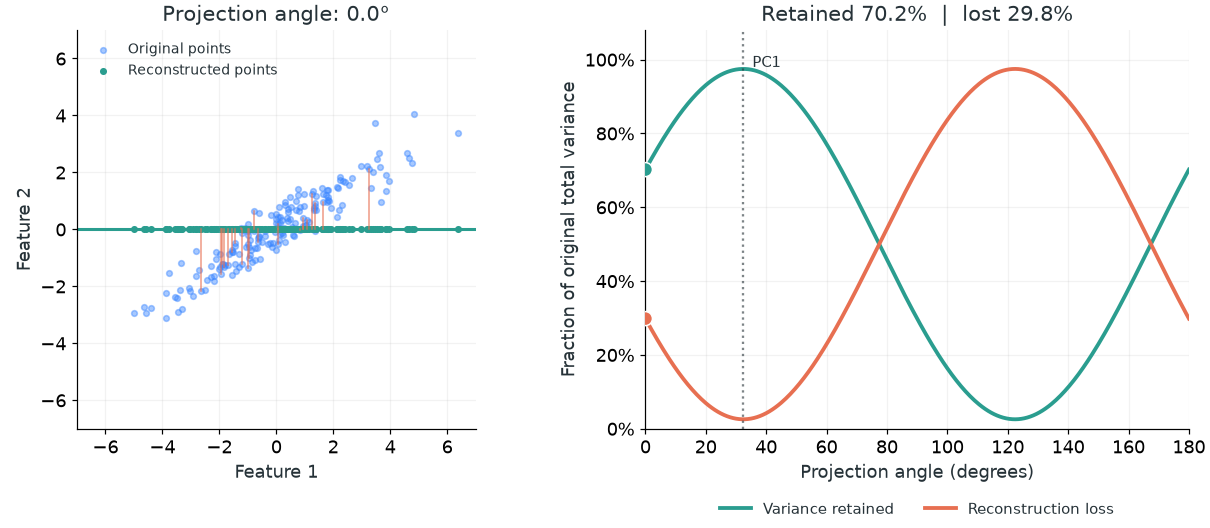

In [17]:
rng = np.random.default_rng(42)
theta = np.deg2rad(32)
rotation = np.array([[np.cos(theta), -np.sin(theta)], [np.sin(theta), np.cos(theta)]])
cloud = (rng.normal(size=(180, 2)) * [2.5, .45]) @ rotation.T
cloud -= cloud.mean(axis=0)
cloud_pca = PCA().fit(cloud)
best_angle = np.rad2deg(np.arctan2(*cloud_pca.components_[0, ::-1])) % 180
angle_grid = np.linspace(0, 180, 361)
directions = np.c_[np.cos(np.deg2rad(angle_grid)), np.sin(np.deg2rad(angle_grid))]
total_variance = (cloud ** 2).sum(axis=1).mean()
retained = (cloud @ directions.T).var(axis=0) / total_variance
projection_frames = []
for angle in sorted(set(np.r_[np.arange(0, 181, 10), best_angle])):
    direction = np.array([np.cos(np.deg2rad(angle)), np.sin(np.deg2rad(angle))])
    shadow = (cloud @ direction)[:, None] * direction
    kept = (cloud @ direction).var() / total_variance
    error = ((cloud - shadow) ** 2).sum(axis=1).mean()
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), layout='constrained')
    ax = axes[0]
    ax.scatter(*cloud.T, s=14, color=BLUE, alpha=.45, label='Original points')
    ax.plot(*np.outer([-7, 7], direction).T, color=TEAL, lw=2)
    ax.scatter(*shadow.T, s=13, color=TEAL, label='Reconstructed points')
    for point, projected in zip(cloud[::8], shadow[::8]):
        ax.plot(*np.vstack([point, projected]).T, color=CORAL, lw=1, alpha=.7)
    ax.set(xlim=(-7, 7), ylim=(-7, 7), xlabel='Feature 1', ylabel='Feature 2',
           title=f'Projection angle: {angle:.1f}°')
    ax.set_aspect('equal'); ax.legend(fontsize=9, loc='upper left')
    axes[1].plot(angle_grid, retained, color=TEAL, lw=2.5, label='Variance retained')
    axes[1].plot(angle_grid, 1-retained, color=CORAL, lw=2.5, label='Reconstruction loss')
    axes[1].axvline(best_angle, color=INK, ls=':', alpha=.6)
    axes[1].text(best_angle+3, .98, 'PC1', fontsize=10, color=INK)
    axes[1].scatter([angle, angle], [kept, error/total_variance], c=[TEAL, CORAL],
                    s=85, edgecolor='white', zorder=3)
    axes[1].set(xlim=(0, 180), ylim=(0, 1.08), xlabel='Projection angle (degrees)',
                ylabel='Fraction of original total variance',
                title=f'Retained {kept:.1%}  |  lost {1-kept:.1%}')
    axes[1].yaxis.set_major_formatter(PercentFormatter(1))
    axes[1].legend(loc='upper center', bbox_to_anchor=(.5, -.15), ncol=2, fontsize=10)
    projection_frames.append((f'Projection at {angle:.1f} degrees', fig))
figure_switch(projection_frames, 'Projection direction:', slider=True)

## 3. Center. Project. Reconstruct.

PCA measures variation around the mean. If we skip centering, the line is forced through the origin; moving the entire dataset can change the answer even though the relationships between points have not changed.

For centered data $X_c = X-\mu$, the singular value decomposition is $X_c=U\Sigma V^\top$. The first $k$ rows of $V^\top$ give our orthonormal projection directions. The reduced coordinates are $Z=X_cV_k$, and the reconstruction is $\hat X=ZV_k^\top+\mu$. The eigenvalues of the sample covariance matrix are $\sigma_j^2/(n-1)$, which also give each component's variance.

Each new direction captures the largest remaining variance while staying perpendicular to the earlier directions. Flipping a direction's sign changes the coordinates, but not the line or the reconstruction.

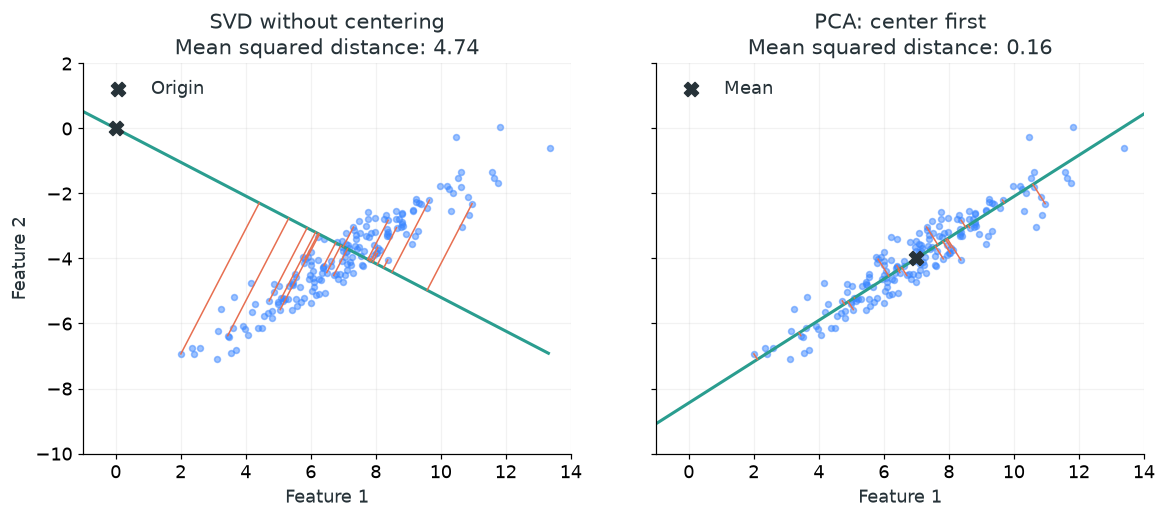

Our one-component reconstruction matches scikit-learn; 97.5% of variance retained.


In [18]:
translated = cloud + [7, -4]
mean = translated.mean(axis=0)
centered = translated - mean
U, singular_values, Vt = np.linalg.svd(centered, full_matrices=False)
k = 1
Z = centered @ Vt[:k].T
reconstruction = Z @ Vt[:k] + mean
variance_ratio = singular_values**2 / (singular_values**2).sum()
reference = PCA(n_components=k).fit(translated)
assert np.allclose(reconstruction, reference.inverse_transform(reference.transform(translated)))

_, _, uncentered_axes = np.linalg.svd(translated, full_matrices=False)
uncentered_reconstruction = (translated @ uncentered_axes[:1].T) @ uncentered_axes[:1]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharex=True, sharey=True, layout='constrained')
for ax, origin, direction, recovered, title in zip(
        axes, [np.zeros(2), mean], [uncentered_axes[0], Vt[0]],
        [uncentered_reconstruction, reconstruction], ['SVD without centering', 'PCA: center first']):
    ax.scatter(*translated.T, color=BLUE, s=15, alpha=.5)
    ax.plot(*(origin + np.outer([-15, 15], direction)).T, color=TEAL, lw=2)
    ax.scatter(*origin, marker='X', s=85, color=INK, zorder=4,
               label='Origin' if np.all(origin == 0) else 'Mean')
    for point, projected in zip(translated[::10], recovered[::10]):
        ax.plot(*np.vstack([point, projected]).T, color=CORAL, lw=1)
    mse = ((translated - recovered)**2).sum(axis=1).mean()
    ax.set(title=f'{title}\nMean squared distance: {mse:.2f}', xlabel='Feature 1',
           xlim=(-1, 14), ylim=(-10, 2))
    ax.set_aspect('equal'); ax.legend(loc='upper left')
axes[0].set_ylabel('Feature 2')
plt.show()
print(f'Our one-component reconstruction matches scikit-learn; {variance_ratio[0]:.1%} of variance retained.')

## 4. How Much Can We Throw Away?

Let's return to the essay embeddings. The cumulative curve tells us how much of their squared variation we retain as we add components. The remainder is reconstruction loss; it is not automatically noise. Thirty components is a practical preprocessing choice for our maps, not a promise to preserve 95% of the variance.

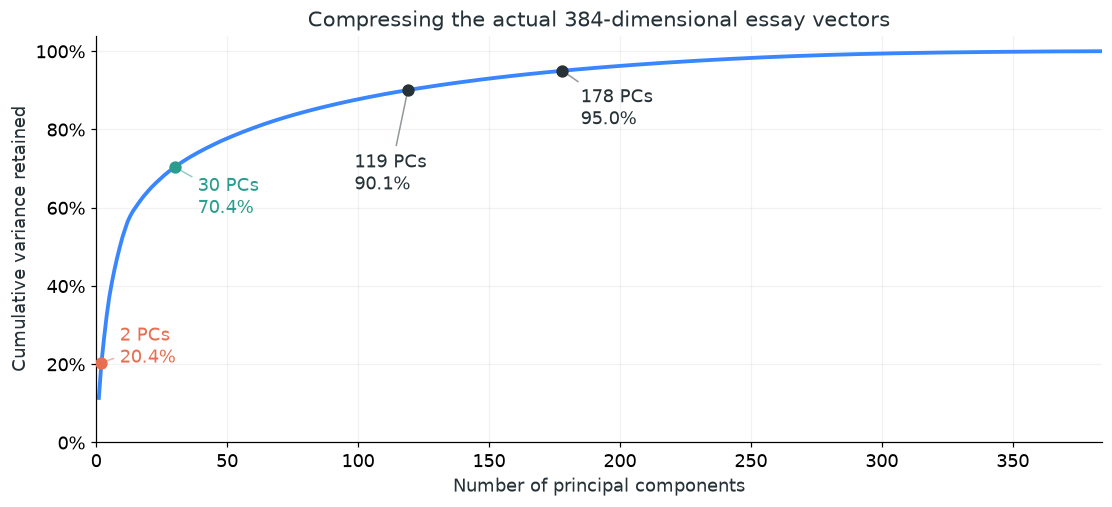

In [19]:
cumulative_variance = text_pca.explained_variance_ratio_.cumsum()
thresholds = np.searchsorted(cumulative_variance, [.90, .95]) + 1
fig, ax = plt.subplots(figsize=(10, 4.5), layout='constrained')
ax.plot(np.arange(1, 385), cumulative_variance, color=BLUE, lw=2.5)
for count, color, offset in [(2, CORAL, (12, 0)), (30, TEAL, (15, -30)),
                              (int(thresholds[0]), INK, (-35, -65)),
                              (int(thresholds[1]), INK, (12, -35))]:
    value = cumulative_variance[count-1]
    ax.scatter(count, value, color=color, zorder=3, s=50)
    ax.annotate(f'{count} PCs\n{value:.1%}', (count, value), xytext=offset,
                textcoords='offset points', color=color,
                arrowprops=dict(arrowstyle='-', color=color, alpha=.5))
ax.set(xlim=(0, 384), ylim=(0, 1.04), xlabel='Number of principal components',
       ylabel='Cumulative variance retained', title='Compressing the actual 384-dimensional essay vectors')
ax.yaxis.set_major_formatter(PercentFormatter(1))
plt.show()

A large variance can also be irrelevant to a prediction task. Here is a deliberately constructed example: two classes differ in a narrow direction, while a much wider direction varies almost independently of the label. PCA never sees those labels. We fit it on the training split, then train the same one-feature logistic classifier using either PC1 or PC2. The histograms use different horizontal ranges to make the overlap visible in both; the variance percentages measure their very different spreads.

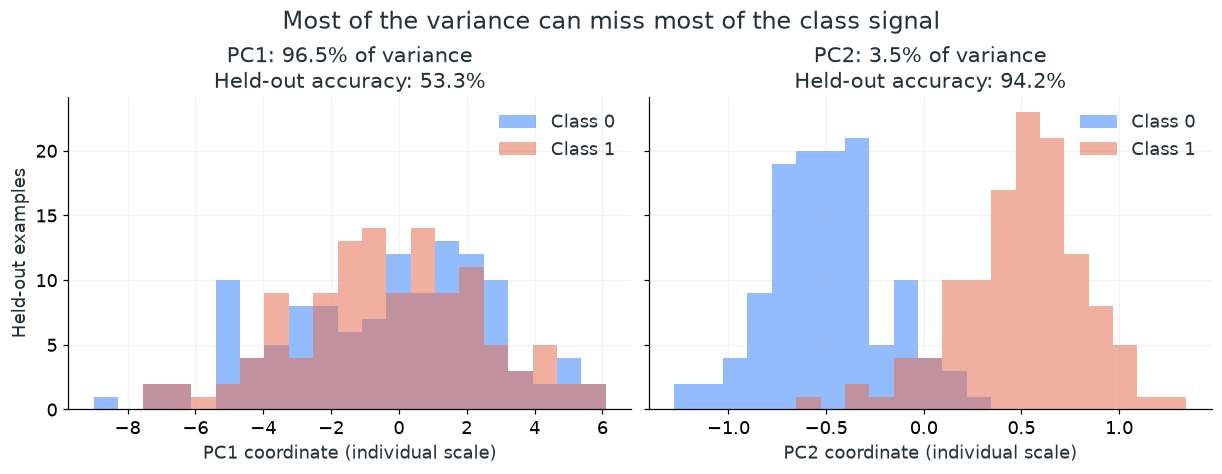

In [20]:
rng = np.random.default_rng(42)
class_labels = np.repeat([0, 1], 400)
class_points = rng.normal(size=(800, 2)) * [3, .3] + np.c_[np.zeros(800), class_labels-.5]
train_ids, test_ids = train_test_split(np.arange(800), test_size=.3, stratify=class_labels, random_state=42)
class_pca = PCA().fit(class_points[train_ids])
train_pc, test_pc = class_pca.transform(class_points[train_ids]), class_pca.transform(class_points[test_ids])
class_accuracies = []
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True, layout='constrained')
for j, ax in enumerate(axes):
    classifier = LogisticRegression().fit(train_pc[:, [j]], class_labels[train_ids])
    accuracy = classifier.score(test_pc[:, [j]], class_labels[test_ids])
    class_accuracies.append(accuracy)
    bins = np.linspace(test_pc[:, j].min()-.1, test_pc[:, j].max()+.1, 22)
    for label, color in enumerate(SOURCE_COLORS):
        ax.hist(test_pc[class_labels[test_ids] == label, j], bins=bins, color=color,
                alpha=.55, label=f'Class {label}')
    ax.set(title=f'PC{j+1}: {class_pca.explained_variance_ratio_[j]:.1%} of variance\n'
                 f'Held-out accuracy: {accuracy:.1%}', xlabel=f'PC{j+1} coordinate (individual scale)')
    ax.legend()
axes[0].set_ylabel('Held-out examples')
fig.suptitle('Most of the variance can miss most of the class signal', fontsize=16)
plt.show()

The narrow direction is useful because of the task, not because it has a large variance. A variance threshold is a compression rule. For prediction, the number of components belongs inside the training-and-validation pipeline.

## 5. Units and Outliers Change the Answer

Centering removes the mean; standardizing also divides each feature by its standard deviation. These solve different problems. Changing meters to centimeters changes the weight a feature receives in PCA's squared-error objective. Standardization removes that dependence on units, but also gives low-variance features more influence, which may or may not suit the problem.

The two panels below use the same synthetic cloud. On the left, every direction is drawn back in the original units so that we can compare them fairly. On the right, we zoom out to include three extreme observations: fewer than 2% of the rows, but enough to turn the fitted direction. Each panel uses equal horizontal and vertical scales. An unusual observation deserves investigation, not automatic deletion.

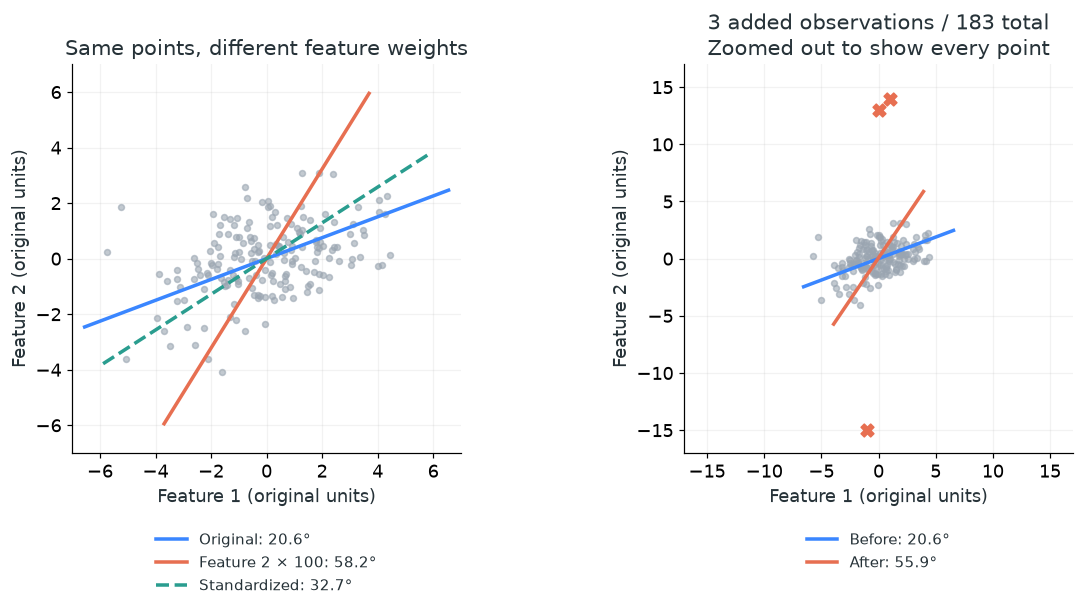

In [21]:
unit_cloud = np.random.default_rng(42).multivariate_normal([0, 0], [[4, 1], [1, 2]], 180)
unit_cloud -= unit_cloud.mean(axis=0)
unit_pca = PCA().fit(unit_cloud)
unit_factors = np.array([1, 100])
scaled_units = unit_cloud * unit_factors
unit_direction = PCA().fit(scaled_units).components_[0] / unit_factors
standardizer = StandardScaler().fit(unit_cloud)
standard_direction = PCA().fit(standardizer.transform(unit_cloud)).components_[0] * standardizer.scale_
outliers = np.array([[0, 13], [1, 14], [-1, -15]])
contaminated = np.vstack([unit_cloud, outliers])
contaminated_pca = PCA().fit(contaminated)


def direction_line(ax, center, direction, color, label, style='-'):
    direction = direction / np.linalg.norm(direction)
    ax.plot(*(center + np.outer([-7, 7], direction)).T, color=color, lw=2.3,
            ls=style, label=label)


def direction_angle(direction):
    return np.rad2deg(np.arctan2(direction[1], direction[0])) % 180


fig, axes = plt.subplots(1, 2, figsize=(11, 5.5), layout='constrained')
for ax, limit in zip(axes, [7, 17]):
    ax.scatter(*unit_cloud.T, s=15, color='#9AA5B1', alpha=.6)
    ax.set(xlabel='Feature 1 (original units)', ylabel='Feature 2 (original units)',
           xlim=(-limit, limit), ylim=(-limit, limit))
    ax.set_aspect('equal')
for direction, color, name, style in [(unit_pca.components_[0], BLUE, 'Original', '-'),
                                     (unit_direction, CORAL, 'Feature 2 × 100', '-'),
                                     (standard_direction, TEAL, 'Standardized', '--')]:
    direction_line(axes[0], unit_cloud.mean(0), direction, color,
                   f'{name}: {direction_angle(direction):.1f}°', style)
axes[0].set_title('Same points, different feature weights')
direction_line(axes[1], unit_cloud.mean(0), unit_pca.components_[0], BLUE,
               f'Before: {direction_angle(unit_pca.components_[0]):.1f}°')
direction_line(axes[1], contaminated.mean(0), contaminated_pca.components_[0], CORAL,
               f'After: {direction_angle(contaminated_pca.components_[0]):.1f}°')
axes[1].scatter(*outliers.T, color=CORAL, marker='X', s=70, zorder=3)
axes[1].set_title(f'3 added observations / {len(contaminated)} total\nZoomed out to show every point')
for ax in axes:
    ax.legend(loc='upper center', bbox_to_anchor=(.5, -.17), fontsize=10)
plt.show()

## 6. A Flat Shadow or a Neighborhood Map?

A digitized [mammoth skeleton](https://github.com/YingfanWang/PaCMAP/tree/master/demo) gives us a real three-dimensional object to recognize. A synthetic Swiss roll gives us a different challenge: a flat sheet has been curled through space. A straight projection can put distant parts of that sheet on top of each other.

PCA uses one linear projection of the whole dataset. t-SNE instead fits a map that emphasizes neighborhood similarities; UMAP builds and embeds a weighted neighborhood graph. Neither nonlinear map promises faithful global distances, island sizes, or gaps. All four views use exactly the same points and colors. For the mammoth, color follows its longest original coordinate; for the roll, it follows position along the sheet.

On the roll, the faint line traces the top edge of the underlying synthetic sheet. A and B are a deliberately selected pair: they are far apart along the sheet's height but nearly overlap in PCA. Follow those same two observations through the other maps.

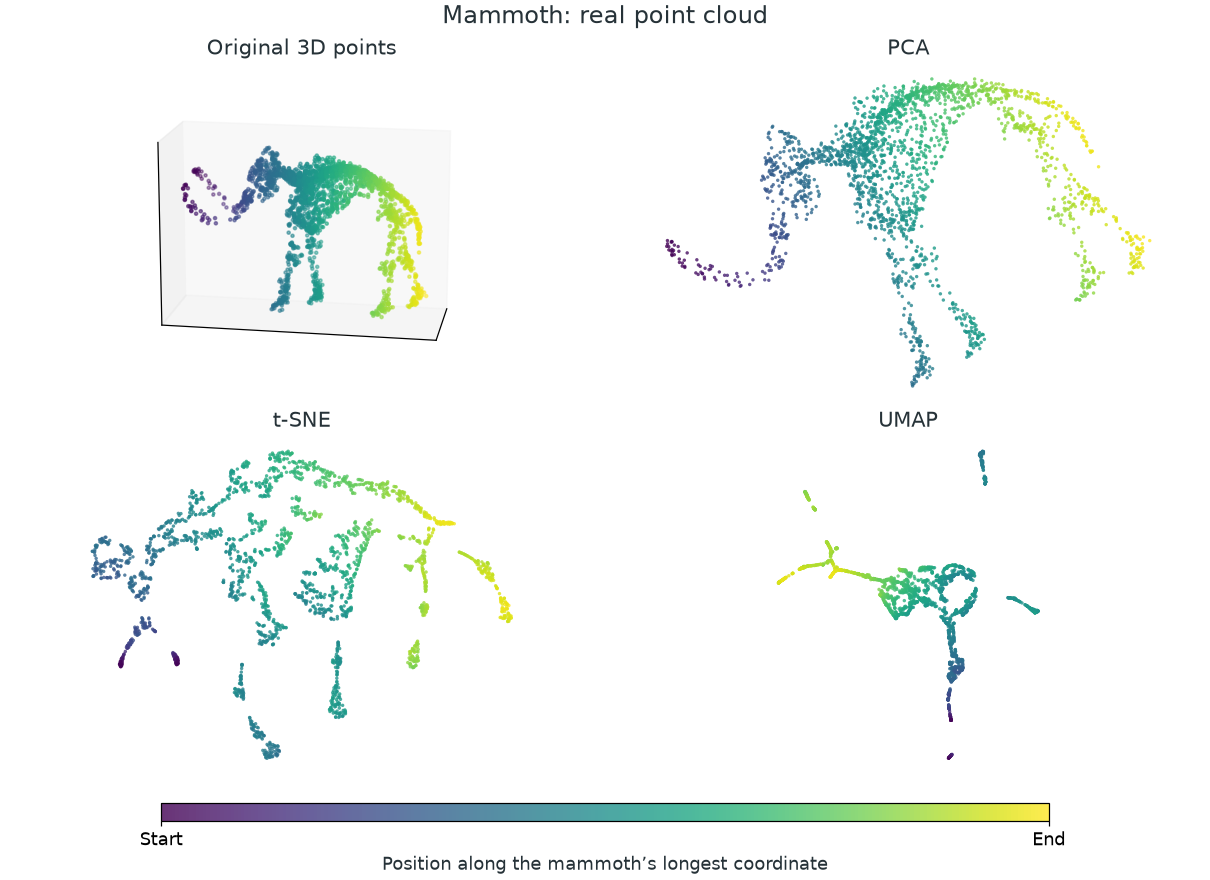

In [22]:
mammoth_all = pd.read_csv(data_dir / 'mammoth_data.csv').to_numpy()
mammoth_rows = np.random.default_rng(42).choice(len(mammoth_all), 2400, replace=False)
mammoth = mammoth_all[mammoth_rows]
roll, roll_color = make_swiss_roll(n_samples=1400, noise=.05, random_state=42)
shapes = {'Mammoth: real point cloud': (mammoth, mammoth[:, np.ptp(mammoth, axis=0).argmax()]),
          'Swiss roll: synthetic surface': (roll, roll_color)}
shape_maps, shape_views = {}, []
for name, (points, colors) in shapes.items():
    with threadpool_limits(limits=1):
        shape_maps[name] = {'PCA': PCA(2).fit_transform(points),
                           't-SNE': tsne_map(points),
                           'UMAP': UMAP(n_neighbors=30, min_dist=.1, random_state=42,
                                        n_jobs=1).fit_transform(points)}
    if 'Swiss roll' in name:
        # Select a concrete example of height information lost in the flat projection.
        eligible = abs(roll[:, None, 1] - roll[:, 1]) > 14
        pca_positions = shape_maps[name]['PCA']
        projected_distance = ((pca_positions[:, None] - pca_positions)**2).sum(axis=2)
        roll_pair = np.unravel_index(np.where(eligible, projected_distance, np.inf).argmin(), eligible.shape)
    fig = plt.figure(figsize=(11, 8), layout='constrained')
    original_ax = fig.add_subplot(2, 2, 1, projection='3d')
    # Put the roll's height on the vertical display axis; this only changes the camera view.
    original_points = points[:, [0, 2, 1]] if 'Swiss roll' in name else points
    dots = original_ax.scatter(*original_points.T, c=colors, cmap='viridis', s=4, alpha=.8)
    original_ax.view_init(elev=15 if 'Mammoth' in name else 55,
                          azim=10 if 'Mammoth' in name else -65)
    original_ax.set_box_aspect(np.ptp(original_points, axis=0))
    original_ax.set(title='Original 3D points', xticks=[], yticks=[], zticks=[])
    if 'Swiss roll' in name:
        edge = np.linspace(1.5*np.pi, 4.5*np.pi, 200)
        original_ax.plot(edge*np.cos(edge), edge*np.sin(edge), np.full_like(edge, 21),
                          color=INK, lw=1, alpha=.4)
        original_gap = np.linalg.norm(points[roll_pair[0]] - points[roll_pair[1]])
        original_ax.set_title(f'Original 3D points\nA–B distance: {original_gap:.2f}')
        for letter, index in zip('AB', roll_pair):
            original_ax.scatter(*original_points[index], s=65, facecolor='white', edgecolor=INK, depthshade=False)
            original_ax.text(*original_points[index], '  '+letter, color=INK, fontsize=13, weight='bold')
    for position, (method, mapped) in enumerate(shape_maps[name].items(), start=2):
        ax = fig.add_subplot(2, 2, position)
        ax.scatter(*mapped.T, c=colors, cmap='viridis', s=5, alpha=.8, linewidths=0)
        map_axes(ax, method)
        if 'Swiss roll' in name:
            if method == 'PCA':
                mapped_gap = np.linalg.norm(mapped[roll_pair[0]] - mapped[roll_pair[1]])
                ax.set_title(f'PCA\nA–B distance: {mapped_gap:.2f} (same units)')
            for letter, index in zip('AB', roll_pair):
                outward = mapped[index] - mapped[list(roll_pair)].mean(axis=0)
                offset = np.clip(24 * outward / max(np.linalg.norm(outward), 1e-8), [-24, -12], [24, 12])
                ax.scatter(*mapped[index], s=65, facecolor='white', edgecolor=INK, zorder=4)
                ax.annotate(letter, mapped[index], xytext=offset, textcoords='offset points',
                            fontsize=13, weight='bold', zorder=5, ha='center', va='center',
                            bbox=dict(facecolor='white', edgecolor='none', alpha=.85, pad=1),
                            arrowprops=dict(arrowstyle='-', color=INK))
    colorbar = fig.colorbar(dots, ax=fig.axes, location='bottom', fraction=.025, pad=.04, aspect=50)
    colorbar.set_ticks([colors.min(), colors.max()], labels=['Start', 'End'])
    colorbar.set_label('Position along the sheet' if 'Swiss roll' in name
                       else 'Position along the mammoth’s longest coordinate')
    fig.suptitle(name, fontsize=16)
    shape_views.append((name, fig))
figure_switch(shape_views, 'Dataset:')

The target matters. A recognizable silhouette and an unfolded surface are different goals. A nonlinear method can emphasize local groups while losing the overall shape; a linear projection can retain a shape while overlapping its layers. Separating class labels is not PCA's objective.

How much of a nonlinear map comes from its settings? These observations all came from one connected sheet, yet some settings make the sample look like separate islands. t-SNE's *perplexity* changes the effective neighborhood scale. UMAP's `n_neighbors` changes the graph's neighborhood scale, while `min_dist` influences how tightly points pack in the map. They are related choices, not interchangeable parameters. Here the data and random seed stay fixed; UMAP's `min_dist` stays at 0.1. Rotation and orientation have no intrinsic meaning in these maps; look instead at fragmentation and the continuity of the color sequence.

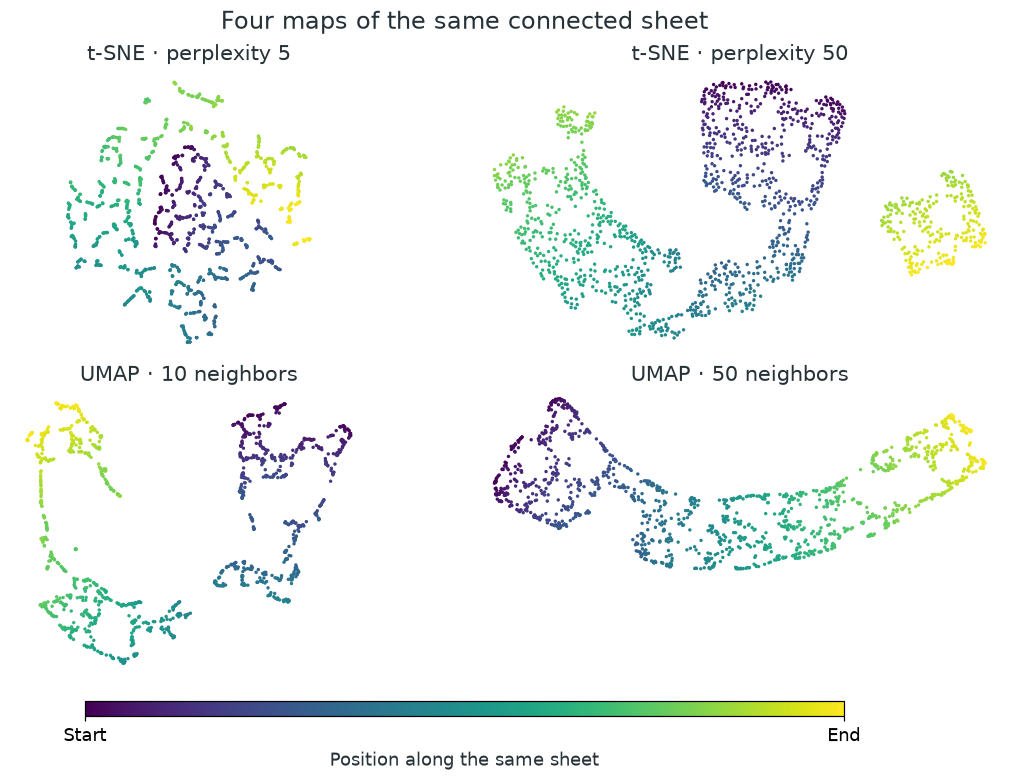

In [23]:
setting_maps = [('t-SNE · perplexity 5', tsne_map(roll, 5)),
                ('t-SNE · perplexity 50', tsne_map(roll, 50))]
with threadpool_limits(limits=1):
    for neighbors in [10, 50]:
        mapped = UMAP(n_neighbors=neighbors, min_dist=.1, random_state=42, n_jobs=1).fit_transform(roll)
        setting_maps.append((f'UMAP · {neighbors} neighbors', mapped))
fig, axes = plt.subplots(2, 2, figsize=(10, 7), layout='constrained')
for ax, (name, mapped) in zip(axes.flat, setting_maps):
    dots = ax.scatter(*mapped.T, c=roll_color, cmap='viridis', s=5, linewidths=0)
    map_axes(ax, name)
    ax.set_anchor('N')
colorbar = fig.colorbar(dots, ax=axes, location='bottom', fraction=.025, pad=.04, aspect=50, panchor=False)
colorbar.set_ticks([roll_color.min(), roll_color.max()], labels=['Start', 'End'])
colorbar.set_label('Position along the same sheet')
fig.suptitle('Four maps of the same connected sheet', fontsize=16)
plt.show()

## 7. One Prompt, Fewer Explanations?
Every essay here answers the same question: “Does the electoral college work?” Do human and AI essays still form different groups?
On the left, the curves compare essay lengths; their halfway points give the medians. On the right, the same essays stay in place while we color them by origin, model family, or length. Which best explains the pattern? Holding the prompt fixed removes one possible explanation—not all of them.

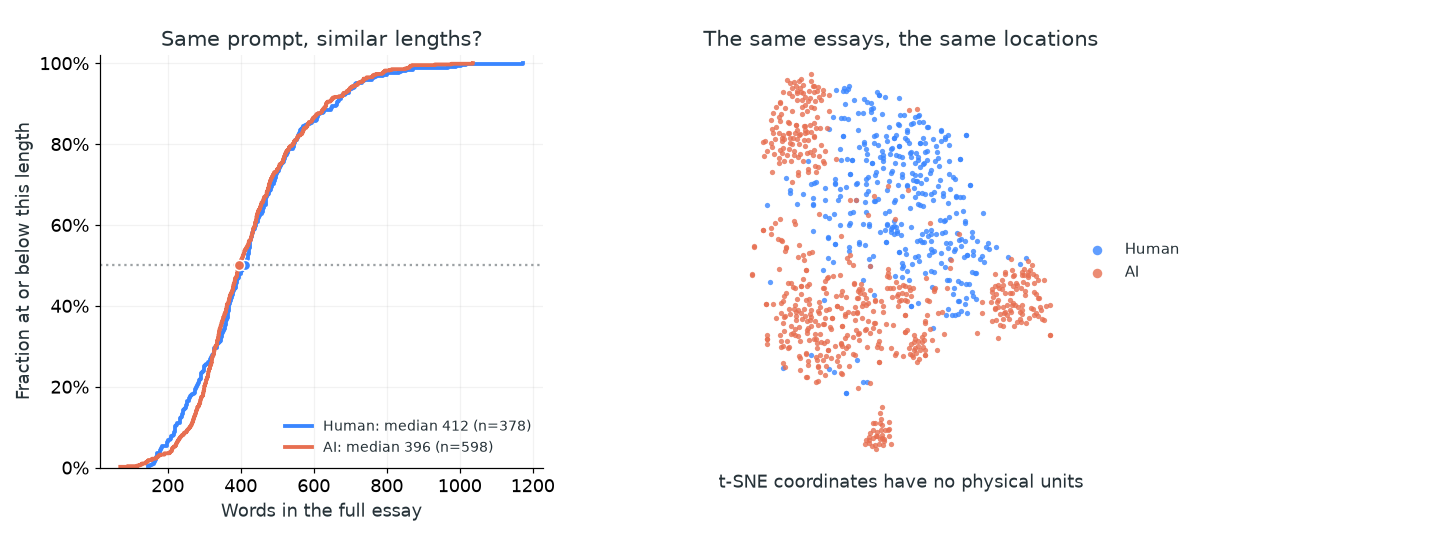

In [24]:
prompt_mask = essays.prompt_name.eq('Does the electoral college work?').to_numpy()
prompt_meta = essays.loc[prompt_mask].reset_index(drop=True)
prompt_vectors = embeddings[prompt_mask]
with threadpool_limits(limits=1):
    prompt_pca = PCA(30, svd_solver='full').fit(prompt_vectors)
    prompt_scores = prompt_pca.transform(prompt_vectors)
prompt_map = tsne_map(prompt_scores)
prompt_views = []
for field, name in [('label', 'Recorded origin'), ('model', 'Recorded model family'),
                    ('word_count', 'Essay length')]:
    fig = plt.figure(figsize=(13, 5))
    axes = [fig.add_axes([.07, .15, .31, .75]), fig.add_axes([.44, .15, .38, .75])]
    for label, color in enumerate(SOURCE_COLORS):
        lengths = np.sort(prompt_meta.loc[prompt_meta.label == label, 'word_count'])
        axes[0].step(lengths, np.arange(1, len(lengths)+1)/len(lengths), where='post', color=color,
                     lw=2.5, label=f'{["Human", "AI"][label]}: median {np.median(lengths):.0f} (n={len(lengths)})')
        axes[0].scatter(np.median(lengths), .5, color=color, edgecolor='white', s=45, zorder=3)
    axes[0].axhline(.5, color=INK, ls=':', alpha=.45)
    axes[0].set(xlabel='Words in the full essay', ylabel='Fraction at or below this length',
                title='Same prompt, similar lengths?', ylim=(0, 1.02))
    axes[0].yaxis.set_major_formatter(PercentFormatter(1)); axes[0].legend(loc='lower right', fontsize=9)
    colored_text_map(axes[1], prompt_map, prompt_meta, field)
    prompt_views.append((name, fig))
figure_switch(prompt_views, 'Color by:')

## Wrap-Up

Dimensionality reduction makes a choice about what to preserve. PCA keeps directions of large variance and gives a measurable reconstruction trade-off, but units, outliers, and the prediction task can change what counts as useful. t-SNE and UMAP help us inspect neighborhoods, while their settings can reshape the picture. In the essay example, the map helps us ask about topic, source, and length; answering those questions requires checking the original representation and testing our explanations beyond the map.

**Further reading:** [PCA and its SVD implementation](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html), [the t-SNE paper](https://jmlr.org/papers/v9/vandermaaten08a.html), [the UMAP paper](https://arxiv.org/abs/1802.03426), and [UMAP parameter examples](https://umap-learn.readthedocs.io/en/latest/parameters.html).